# FT-Transformer clinical expert — independent test evaluation

This notebook evaluates the source-specific FT-Transformer prediction exports created by `03_training/biomarkers/cardiac_biomarker_ft_transformer.ipynb`. It does not retrain models, refit preprocessing, select thresholds on test data or combine different dataset targets.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, f1_score, confusion_matrix, ConfusionMatrixDisplay

def find_root(start=None):
    current = Path(start or Path.cwd()).resolve()
    for p in [current, *current.parents]:
        if (p / "src").is_dir() and (p / "config").is_dir(): return p
        if (p / "ml-service" / "src").is_dir(): return p / "ml-service"
    raise FileNotFoundError("Could not find ml-service.")
ML_ROOT = find_root()
if str(ML_ROOT) not in sys.path: sys.path.insert(0, str(ML_ROOT))
ARTIFACT_ROOT = ML_ROOT / "artifacts" / "metrics" / "biomarkers" / "ft_transformer"
SOURCES = ["zheen", "framingham", "uci_heart_failure", "mi_complications"]

## 1. Load test prediction exports and validate their schema

In [2]:
frames = []
for source in SOURCES:
    path = ARTIFACT_ROOT / source / "test_predictions.csv"
    if not path.is_file():
        print(f"[MISSING] {path} — run the FT-Transformer training notebook first.")
        continue
    frame = pd.read_csv(path)
    required = {"dataset", "target", "split", "row_index", "true", "prediction", "output_type"}
    missing = sorted(required - set(frame.columns))
    if missing: raise ValueError(f"{path} misses columns: {missing}")
    if set(frame["split"].dropna().unique()) != {"test"}:
        raise ValueError(f"{path} contains non-test rows; refusing to report it as held-out test evaluation.")
    frames.append(frame)
if not frames: raise FileNotFoundError("No FT-Transformer test prediction files found.")
predictions = pd.concat(frames, ignore_index=True)
display(predictions.head())

,dataset,target,split,row_index,true,prediction,output_type,class_index
0,zheen,acute_mi,test,0,1,0.986949,binary_probability,NaN
1,zheen,acute_mi,test,1,0,0.013874,binary_probability,NaN
2,zheen,acute_mi,test,2,0,0.011384,binary_probability,NaN
3,zheen,acute_mi,test,3,1,0.985215,binary_probability,NaN
4,zheen,acute_mi,test,4,1,0.987212,binary_probability,NaN


## 2. Calculate per-source, per-target test metrics

Binary probabilities and multiclass distributions are reported separately. Metrics are not aggregated across the four different clinical populations or endpoint meanings.

In [3]:
def evaluate_binary(group):
    y = pd.to_numeric(group["true"], errors="coerce").to_numpy(dtype=float)
    p = pd.to_numeric(group["prediction"], errors="coerce").to_numpy(dtype=float)
    valid = np.isfinite(y) & np.isfinite(p); y, p = y[valid].astype(int), p[valid]
    if len(y) == 0 or len(np.unique(y)) < 2:
        return {"status": "not_computable_single_class_or_no_rows", "n": int(len(y))}
    return {"status": "computed", "n": int(len(y)), "auroc": float(roc_auc_score(y,p)),
            "auprc": float(average_precision_score(y,p)), "brier": float(brier_score_loss(y,p)),
            "f1_at_0_5": float(f1_score(y,p>=0.5,zero_division=0))}

results=[]
for (dataset, target, output_type), group in predictions.groupby(["dataset","target","output_type"]):
    if output_type == "binary_probability":
        metrics=evaluate_binary(group)
    elif output_type == "multiclass_class_probability":
        distributions=[]; truths=[]
        for _, row_group in group.sort_values(["row_index","class_index"]).groupby("row_index"):
            probs=row_group["prediction"].to_numpy(dtype=float)
            labels=row_group["class_index"].to_numpy(dtype=int)
            if len(probs)<2 or not np.isfinite(probs).all() or not np.array_equal(labels,np.arange(len(probs))): continue
            probs=probs/probs.sum(); distributions.append(probs); truths.append(int(row_group["true"].iloc[0]))
        if distributions:
            from sklearn.metrics import accuracy_score, f1_score, log_loss
            p=np.asarray(distributions); y=np.asarray(truths); pred=p.argmax(axis=1)
            metrics={"status":"computed","n":len(y),"accuracy":float(accuracy_score(y,pred)),
                     "macro_f1":float(f1_score(y,pred,average="macro",zero_division=0)),
                     "log_loss":float(log_loss(y,p,labels=list(range(p.shape[1]))))}
        else: metrics={"status":"no_complete_multiclass_rows"}
    else: metrics={"status":"unsupported_output_type"}
    results.append({"dataset":dataset,"target":target,"output_type":output_type,**metrics})
results_df=pd.DataFrame(results)
display(results_df)
output=ML_ROOT / "artifacts" / "metrics" / "biomarkers" / "ft_transformer" / "aggregate_test_evaluation.csv"
output.parent.mkdir(parents=True,exist_ok=True); results_df.to_csv(output,index=False)
print("Saved:", output)

,dataset,target,output_type,status,n,auroc,auprc,brier,f1_at_0_5,accuracy,macro_f1,log_loss
0,framingham,ten_year_chd_risk,binary_probability,computed,636,0.678607,0.287719,0.217046,0.310559,NaN,NaN,NaN
1,mi_complications,a_v_blok,binary_probability,computed,255,0.843270,0.138175,0.151629,0.176471,NaN,NaN,NaN
2,mi_complications,dressler,binary_probability,computed,255,0.647807,0.081438,0.232666,0.141593,NaN,NaN,NaN
3,mi_complications,fibr_jelud,binary_probability,computed,255,0.655375,0.076556,0.236763,0.079208,NaN,NaN,NaN
4,mi_complications,fibr_preds,binary_probability,computed,255,0.547826,0.142213,0.258600,0.208333,NaN,NaN,NaN
5,mi_complications,jelud_tah,binary_probability,computed,255,0.598178,0.048797,0.168503,0.081081,NaN,NaN,NaN
6,mi_complications,let_is,multiclass_class_probability,computed,255,NaN,NaN,NaN,NaN,0.85098,0.11518,0.662964
7,mi_complications,o_l_post,binary_probability,computed,254,0.818704,0.226771,0.154058,0.205882,NaN,NaN,NaN
8,mi_complications,p_im_sten,binary_probability,computed,255,0.584708,0.125650,0.256211,0.196078,NaN,NaN,NaN
9,mi_complications,preds_tah,binary_probability,computed,255,0.718254,0.026507,0.177885,0.000000,NaN,NaN,NaN


Saved: D:\Programming\VS Code\Projects\CardioFusion-XAI\ml-service\artifacts\metrics\biomarkers\ft_transformer\aggregate_test_evaluation.csv


## 3. Per-target probability diagnostics

For binary endpoints, inspect the score distributions by true class. These plots are diagnostics only; do not tune a threshold on the test set.

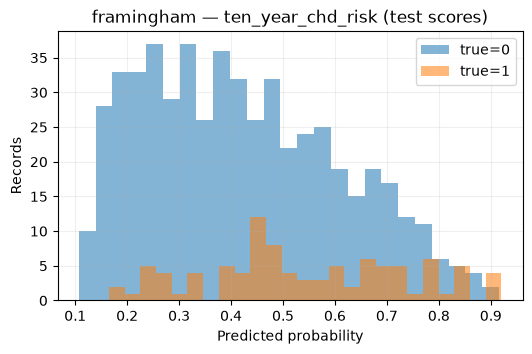

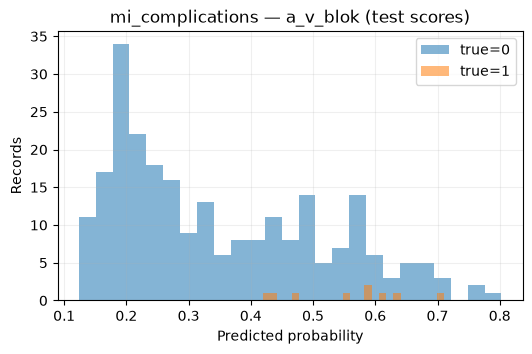

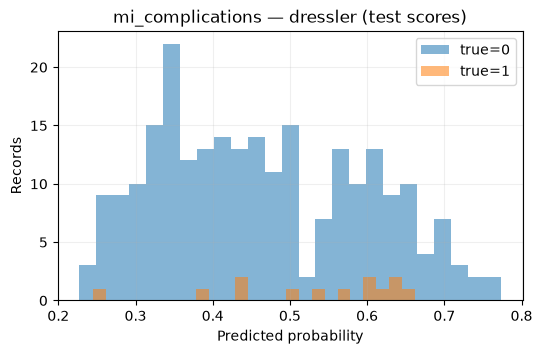

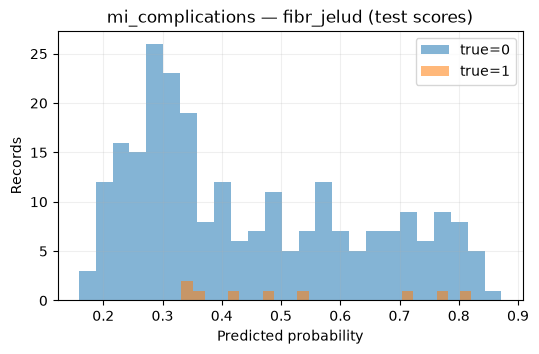

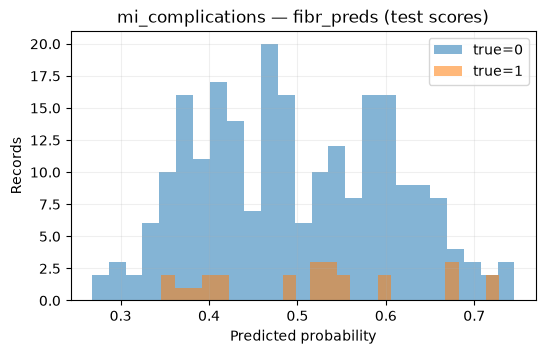

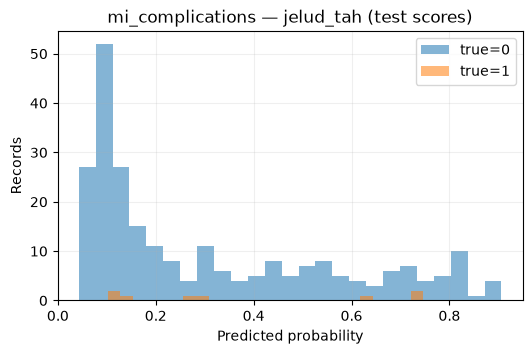

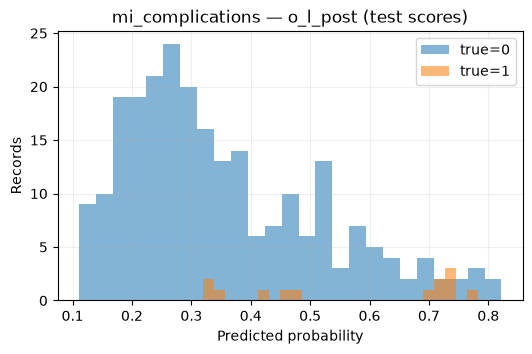

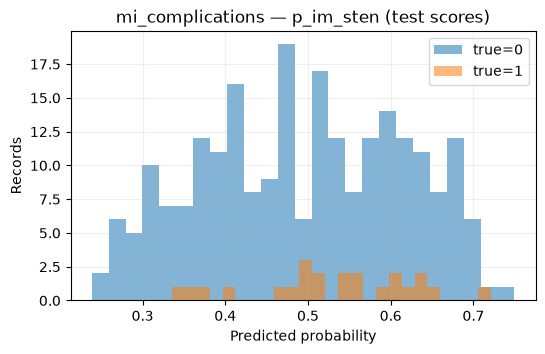

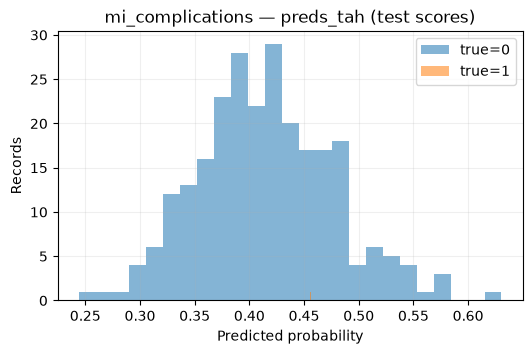

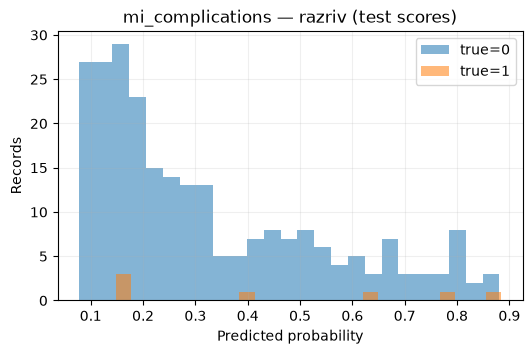

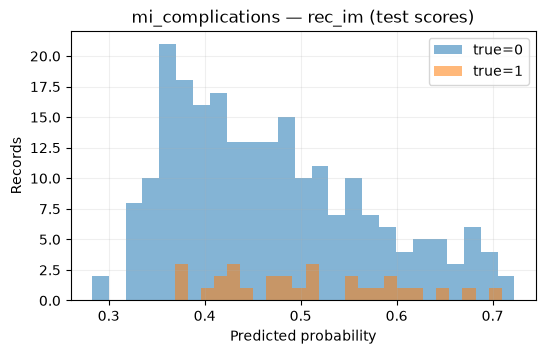

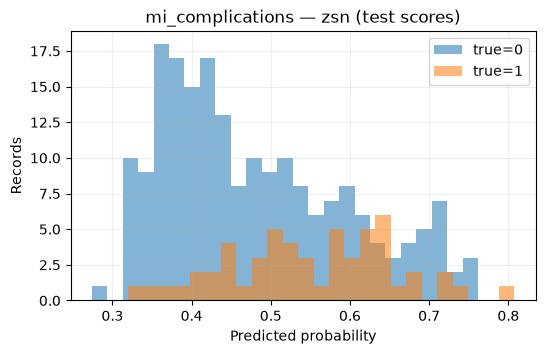

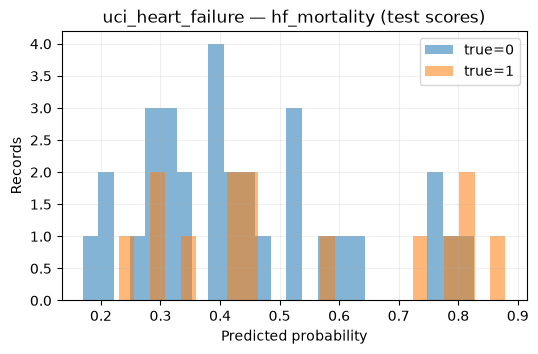

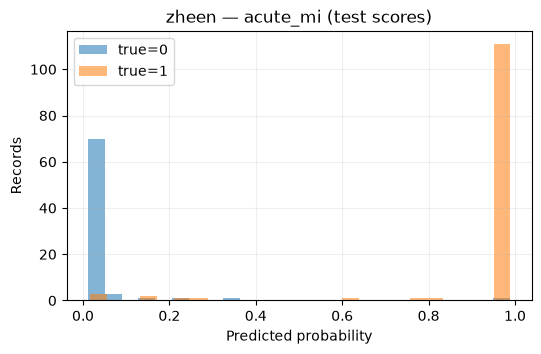

In [4]:
for (dataset,target), group in predictions[predictions["output_type"]=="binary_probability"].groupby(["dataset","target"]):
    plt.figure(figsize=(6,3.5))
    for label, subset in group.groupby("true"):
        plt.hist(subset["prediction"], bins=25, alpha=0.55, label=f"true={label}")
    plt.title(f"{dataset} — {target} (test scores)"); plt.xlabel("Predicted probability"); plt.ylabel("Records")
    plt.legend(); plt.grid(alpha=0.2); plt.show()

## 4. Reporting restrictions

Do not report one combined AUROC or probability for all four clinical datasets. The outcomes and cohorts are different. Include sample counts, uncertainty intervals where calculated, the exact data source and split methodology, and whether a calibration artifact was fitted using validation predictions.